# Randomized Benchmarking

Python companion to the AMO Toolkit page [Randomized Benchmarking](https://amotoolkit.com/pages/rb-explorer.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/rb-explorer.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. The decay model
Sequence fidelity $F(m) = A p^m + B$ with $B = 1/d$. The error per Clifford is $r_C = (d-1)(1-p)/d$: $p = 1-2r_C$ for one qubit and $p = 1 - \tfrac43 r_C$ for two. SPAM changes A and B, not p. The page also quotes the usual conversion to a per-gate error, ε ≈ r<sub>C</sub>/1.875 (1.875 physical gates per Clifford on average for a common single-qubit gate set).

{'p': 0.99, 'rC_pct': 0.5, 'eps_gate_pct': 0.26666666666666666, 'N_useful': 100, 'F_avg_pct': 99.73333333333333, 'A': 0.44999999999999996}
{'p_ref': 0.99, 'p_int': 0.9801, 'ratio': 0.99, 'r_gate_pct': 0.5000000000000004}

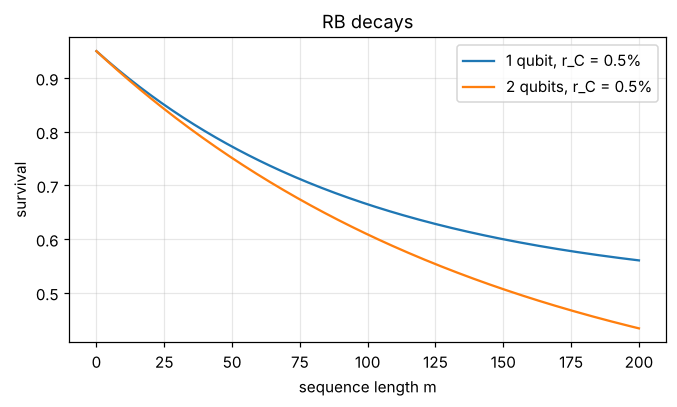

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def rb(rC=0.005, F0=0.95):
    p = 1 - 2 * rC
    eps = rC / 1.875
    return dict(p=p, rC_pct=100 * rC, eps_gate_pct=100 * eps, N_useful=round(1 / (2 * rC)), F_avg_pct=100 * (1 - eps), A=F0 - 0.5)

def irb(rC=0.005, r_gate=0.005):
    p_ref = 1 - 2 * rC; p_int = p_ref * (1 - 2 * r_gate)
    return dict(p_ref=p_ref, p_int=p_int, ratio=p_int / p_ref, r_gate_pct=100 * 0.5 * (1 - p_int / p_ref))

r1, r2 = rb(), irb()
print(r1); print(r2)
m = np.arange(0, 201)
plt.plot(m, r1["A"] * r1["p"] ** m + 0.5, label="1 qubit, r_C = 0.5%")
plt.plot(m, (0.95 - 0.25) * (1 - 4 / 3 * 0.005) ** m + 0.25, label="2 qubits, r_C = 0.5%")
plt.xlabel("sequence length m"); plt.ylabel("survival"); plt.legend(); plt.title("RB decays")

## 2. A real (simulated) RB experiment
Build the 24 single-qubit Cliffords, run random sequences followed by the inverting Clifford, add noise after every Clifford, and fit. Two noise models with the same average infidelity: depolarizing, and a coherent over-rotation about z. RB twirls the coherent error into a depolarizing one, so both give the same decay (in expectation), which is exactly why RB reports an *average* error. Coherent errors scatter much more from one random sequence to the next, so they need many more sequences for the same precision (try `seqs=60`).

Clifford group size: 24
             depolarizing: fitted r_C = 0.500%  (set 0.500%)
 coherent z over-rotation: fitted r_C = 0.528%  (set 0.500%)

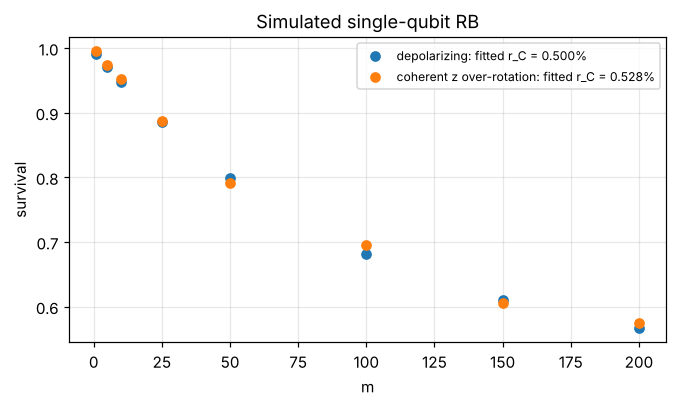

In [2]:
rng = np.random.default_rng(1)
I2 = np.eye(2); H = np.array([[1, 1], [1, -1]]) / np.sqrt(2); S = np.diag([1, 1j])
def key(U):                                   # identify unitaries up to global phase
    k = np.argmax(np.abs(U.ravel()) > 1e-6); U = U * np.exp(-1j * np.angle(U.ravel()[k]))
    return tuple(np.round(U.ravel(), 6))
cl, seen, frontier = [], set(), [I2]
while frontier:
    U = frontier.pop()
    if key(U) in seen: continue
    seen.add(key(U)); cl.append(U); frontier += [H @ U, S @ U]
print("Clifford group size:", len(cl))

def run_rb(noise, lengths=(1, 5, 10, 25, 50, 100, 150, 200), seqs=400):
    out = []
    for m_ in lengths:
        surv = []
        for _ in range(seqs):
            rho = np.array([[1, 0], [0, 0]], complex); U_tot = I2
            for _ in range(m_):
                C = cl[rng.integers(24)]; U_tot = C @ U_tot
                rho = noise(C @ rho @ C.conj().T)
            Cinv = U_tot.conj().T
            rho = noise(Cinv @ rho @ Cinv.conj().T)
            surv.append(rho[0, 0].real)
        out.append(np.mean(surv))
    return np.array(lengths), np.array(out)

r_target = 0.005
dep = lambda rho, q=2 * r_target: (1 - q) * rho + q * np.trace(rho) * I2 / 2
theta = 2 * np.arcsin(np.sqrt(1.5 * r_target)); Rz = np.diag([np.exp(-1j * theta / 2), np.exp(1j * theta / 2)])
coh = lambda rho: Rz @ rho @ Rz.conj().T
from scipy.optimize import curve_fit
for name, noise in (("depolarizing", dep), ("coherent z over-rotation", coh)):
    L, Fm = run_rb(noise)
    (A, p, B), _ = curve_fit(lambda x, A, p, B: A * p**x + B, L, Fm, p0=(0.5, 0.99, 0.5))
    plt.plot(L, Fm, "o", label=f"{name}: fitted r_C = {100*(1-p)/2:.3f}%")
    print(f"{name:>25}: fitted r_C = {100*(1-p)/2:.3f}%  (set {100*r_target:.3f}%)")
plt.xlabel("m"); plt.ylabel("survival"); plt.legend(fontsize=8); plt.title("Simulated single-qubit RB")

## 3. Check against the page

In [3]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(p=r1["p"], rC_pct=r1["rC_pct"], eps_gate_pct=r1["eps_gate_pct"], N_useful=r1["N_useful"], F_avg_pct=r1["F_avg_pct"],
            p_int=r2["p_int"], ratio=r2["ratio"], r_gate_pct=r2["r_gate_pct"])
DECIMALS = dict(p=5, rC_pct=3, eps_gate_pct=3, F_avg_pct=3, p_int=5, ratio=4, r_gate_pct=3)
page = dict(p=0.99, rC_pct=0.5, eps_gate_pct=0.267, N_useful=100, F_avg_pct=99.733, p_int=0.9801, ratio=0.99, r_gate_pct=0.5)
check(ours, page)

           p: notebook 0.99         page 0.99       OK
      rC_pct: notebook 0.5          page 0.5        OK
eps_gate_pct: notebook 0.2667       page 0.267      OK
    N_useful: notebook 100          page 100        OK
   F_avg_pct: notebook 99.73        page 99.733     OK
       p_int: notebook 0.9801       page 0.9801     OK
       ratio: notebook 0.99         page 0.99       OK
  r_gate_pct: notebook 0.5          page 0.5        OK
All values match the page.